# Contoh Absensi Suara VoiceAttend

<a href="https://colab.research.google.com/github/alvingnwns/aol-deeplearning/blob/main/notebooks/contoh_absensi_suara.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Notebook ini menjalankan modul AI `backend/app/ai` dari awal sampai akhir dengan data di folder `notebooks/contoh_data/`:

1. **Naskah**: kalimat yang harus diucapkan mahasiswa (`naskah.csv`).
2. **Manifest**: CSV yang menghubungkan setiap file audio dengan NIM, jenis (daftar/uji), dan label harapan (`manifest.csv`).
3. **Pendaftaran**: 3+ klip per mahasiswa → `VoiceAI.enroll` → *voiceprint* 768 byte, disimpan ke SQLite seperti di backend.
4. **Inferensi**: setiap klip uji → `VoiceAI.verify` → keputusan `present` / `retry` / `rejected`, ditulis ke `hasil/hasil_inferensi.csv`.
5. **Validasi**: akurasi, FAR, FRR, sebaran skor, dan saran ambang (`THRESHOLD`).
6. **Coba audio sendiri**: cek file mana pun, atau rekam langsung dari mikrofon di Colab.

```
naskah.csv ──▶ mahasiswa merekam ──▶ audio/daftar/<NIM>/*.wav ─┐
                                    audio/uji/*.wav ───────────┤
                                                               ▼
                         manifest.csv (file ↔ NIM ↔ harapan) ──▶ notebook ini
                                                               │
              VoiceAI.enroll ──▶ voiceprints.db ──▶ VoiceAI.verify ──▶ hasil/hasil_inferensi.csv
```

Tidak ada pelatihan ulang di sini. Model ECAPA-TDNN sudah dilatih pada ribuan pembicara, jadi menambah mahasiswa cukup dengan membuat voiceprint baru (*append-only*). Di Colab, jalankan **Runtime → Run all**. CPU sudah cukup; GPU hanya mempercepat.

## 1. Persiapan

Di Colab, sel ini meng-*clone* repo dan memasang `speechbrain`. Di komputer sendiri, jalankan notebook dari dalam repo dengan `speechbrain` dan `pandas` terpasang. Ganti `BRANCH` jika ingin mencoba branch yang belum di-*merge*.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/alvingnwns/aol-deeplearning.git"
BRANCH = "main"
DI_COLAB = "google.colab" in sys.modules

if DI_COLAB:
    REPO = Path("/content/aol-deeplearning")
    if not REPO.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--branch", BRANCH, REPO_URL, str(REPO)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "speechbrain>=1.1,<2"], check=True)
else:
    REPO = next(folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / "backend" / "app" / "ai").is_dir())

sys.path.insert(0, str(REPO / "backend"))
print("Berjalan di Colab:", DI_COLAB)
print("Modul AI ditemukan:", (REPO / "backend" / "app" / "ai").is_dir())

Berjalan di Colab: False
Modul AI ditemukan: True


### Folder data

Secara bawaan notebook memakai `notebooks/contoh_data/`. Untuk memakai rekaman tim sendiri, isi `FOLDER_DATA_SENDIRI` dengan folder yang strukturnya sama (lihat `notebooks/contoh_data/README.md`), misalnya `/content/drive/MyDrive/voiceattend_data`. Google Drive akan di-*mount* otomatis.

In [2]:
FOLDER_DATA_SENDIRI = ""

if DI_COLAB and FOLDER_DATA_SENDIRI.startswith("/content/drive"):
    from google.colab import drive

    drive.mount("/content/drive")

DATA = Path(FOLDER_DATA_SENDIRI) if FOLDER_DATA_SENDIRI else REPO / "notebooks" / "contoh_data"
HASIL = DATA / "hasil"
HASIL.mkdir(parents=True, exist_ok=True)
print("Folder data:", DATA.name)
print("Isi:", sorted(path.name for path in DATA.iterdir()))

Folder data: contoh_data
Isi: ['README.md', 'audio', 'hasil', 'mahasiswa.csv', 'manifest.csv', 'naskah.csv', 'sumber_audio.csv']


## 2. Naskah: apa yang harus diucapkan

`K01`–`K03` wajib saat pendaftaran (satu file per kalimat), `K04`–`K05` opsional. `U01` diucapkan saat absen, dengan 6 angka acak dari layar supaya rekaman lama tidak bisa diputar ulang.

Model ini *text-independent*: ia mengenali **siapa** yang bicara, bukan **apa** yang diucapkan. Naskah memastikan setiap klip cukup panjang (3–6 detik) dan berisi bunyi yang beragam.

In [3]:
import pandas as pd

naskah = pd.read_csv(DATA / "naskah.csv", dtype=str).fillna("")
mahasiswa = pd.read_csv(DATA / "mahasiswa.csv", dtype=str)
naskah

,id_kalimat,jenis,kalimat,durasi_detik,catatan
0,K01,daftar,"Nama saya {nama}, nomor induk mahasiswa saya {...",4-6,Ganti {nama} dan {nim} dengan data sendiri
1,K02,daftar,Saya mengikuti mata kuliah Deep Learning dan h...,4-6,
2,K03,daftar,"Satu, dua, tiga, empat, lima, enam, tujuh, del...",4-6,Ucapkan dengan tempo biasa
3,K04,daftar,Pagi ini saya berangkat ke kampus dengan seman...,4-6,Opsional: klip ke-4 membuat voiceprint lebih s...
4,K05,daftar,Kecerdasan buatan dapat mengenali suara setiap...,4-6,Opsional: klip ke-5
5,U01,uji,Saya hadir. Kode saya {kode}.,3-5,{kode} = 6 angka acak yang tampil di layar saa...


## 3. Manifest: menghubungkan audio dengan NIM

Setiap baris adalah satu percobaan. `pemilik_suara` adalah siapa yang sebenarnya bicara (kebenaran untuk validasi), sedangkan `klaim_nim` adalah NIM yang diakui. Jika keduanya berbeda, itu skenario penyusup dan `harapan` harus `tidak_hadir`.

Sel ini juga memeriksa manifest: file harus ada, nilai kolom harus sah, dan setiap NIM butuh minimal 3 klip pendaftaran.

In [4]:
from app.ai import VoiceSettings

manifest = pd.read_csv(DATA / "manifest.csv", dtype=str).fillna("")
JENIS_SAH = {"daftar", "uji"}
HARAPAN_SAH = {"hadir", "tidak_hadir"}
MIN_KLIP = VoiceSettings().min_enroll_clips

masalah = []
for nomor, baris in manifest.iterrows():
    baris_csv = nomor + 2
    if not (DATA / baris.file).is_file():
        masalah.append(f"baris {baris_csv}: file tidak ditemukan: {baris.file}")
    if baris.jenis not in JENIS_SAH:
        masalah.append(f"baris {baris_csv}: jenis '{baris.jenis}' harus daftar atau uji")
    if baris.jenis == "uji" and baris.harapan not in HARAPAN_SAH:
        masalah.append(f"baris {baris_csv}: harapan '{baris.harapan}' harus hadir atau tidak_hadir")
    if baris.id_kalimat and baris.id_kalimat not in set(naskah.id_kalimat):
        masalah.append(f"baris {baris_csv}: id_kalimat '{baris.id_kalimat}' tidak ada di naskah.csv")

daftar = manifest[manifest.jenis == "daftar"]
uji = manifest[manifest.jenis == "uji"]
for nim, jumlah in daftar.groupby("klaim_nim").size().items():
    if jumlah < MIN_KLIP:
        masalah.append(f"NIM {nim}: hanya {jumlah} klip pendaftaran, minimal {MIN_KLIP}")
for nim in sorted(set(daftar.klaim_nim) - set(mahasiswa.nim)):
    masalah.append(f"NIM {nim} ada di manifest tetapi tidak ada di mahasiswa.csv")

assert not masalah, "Manifest bermasalah:\n" + "\n".join(masalah)
print(f"{len(daftar)} klip pendaftaran untuk {daftar.klaim_nim.nunique()} mahasiswa, {len(uji)} percobaan absensi")
manifest.groupby(["klaim_nim", "jenis"]).size().unstack(fill_value=0)

15 klip pendaftaran untuk 5 mahasiswa, 18 percobaan absensi


jenis,daftar,uji
klaim_nim,,
2702000001,3,4
2702000002,3,4
2702000003,3,4
2702000004,3,3
2702000005,3,3


Dengarkan satu klip pendaftaran untuk memastikan audionya benar.

In [5]:
from IPython.display import Audio, display

contoh_klip = daftar.file.iloc[0]
print(contoh_klip)
display(Audio(filename=str(DATA / contoh_klip)))

audio/daftar/2702000001/K01.wav


## 4. Memuat model

`VoiceAI` adalah satu-satunya pintu ke modul AI. Pemanggilan pertama `warm_up()` mengunduh model ECAPA-TDNN (~80 MB) dari Hugging Face. Ambang keputusan diambil dari `VoiceSettings`:

| pengaturan | arti |
|---|---|
| `accept_threshold` | skor minimal agar dianggap mahasiswa yang diklaim |
| `retry_floor` | di bawah ini langsung ditolak; di antara ini dan `accept_threshold` diminta mengulang |
| `min_margin` | skor klaim harus mengungguli teman sekelas paling mirip sebanyak ini |

In [6]:
import torch

from app.ai import AudioRejected, Decision, VoiceAI

settings = VoiceSettings(
    model_dir=Path(os.environ.get("MODEL_DIR", REPO / ".cache" / "models")),
    device="cuda" if torch.cuda.is_available() else "cpu",
)
ai = VoiceAI(settings)
ai.warm_up()
print("Model:", ai.encoder_version)
print("Perangkat:", settings.device)
print(f"accept_threshold={settings.accept_threshold}  retry_floor={settings.retry_floor}  min_margin={settings.min_margin}")

Model: speechbrain/spkrec-ecapa-voxceleb
Perangkat: cpu
accept_threshold=0.3  retry_floor=0.2  min_margin=0.05


## 5. Pendaftaran: membuat voiceprint

Untuk setiap NIM, semua klip `daftar` dikirim ke `ai.enroll(nim, [bytes, ...])`. Modul ini menolak klip yang terlalu pendek atau pelan, dan klip yang terdengar seperti orang lain (`inconsistent_clips`, beserta nomor klipnya). Hasilnya adalah rata-rata embedding 192 dimensi, yaitu *voiceprint*.

In [7]:
pendaftaran = {}
laporan = []
for nim, grup in daftar.groupby("klaim_nim"):
    klip = [(DATA / file).read_bytes() for file in grup.file]
    try:
        pendaftaran[nim] = ai.enroll(nim, klip)
    except AudioRejected as penolakan:
        file_bermasalah = "" if penolakan.clip_index is None else grup.file.iloc[penolakan.clip_index]
        laporan.append({"nim": nim, "status": "gagal", "jumlah_klip": len(klip), "alasan": penolakan.reason.value, "file_bermasalah": file_bermasalah})
        continue
    laporan.append({"nim": nim, "status": "terdaftar", "jumlah_klip": pendaftaran[nim].clip_count, "alasan": "", "file_bermasalah": ""})

laporan_pendaftaran = mahasiswa.merge(pd.DataFrame(laporan), on="nim", how="right")
laporan_pendaftaran.to_csv(HASIL / "pendaftaran.csv", index=False)
laporan_pendaftaran

,nim,nama,status,jumlah_klip,alasan,file_bermasalah
0,2702000001,Mahasiswa A,terdaftar,3,,
1,2702000002,Mahasiswa B,terdaftar,3,,
2,2702000003,Mahasiswa C,terdaftar,3,,
3,2702000004,Mahasiswa D,terdaftar,3,,
4,2702000005,Mahasiswa E,terdaftar,3,,


### Menyimpan voiceprint seperti backend

Backend menyimpan `voiceprint` sebagai BLOB bersama `encoder_version` (skema di `docs/ai-integration.md`). Saat absen, backend mengambil kembali voiceprint seluruh kelas dengan versi encoder yang sama. Sel ini menirukan alur itu dengan file `hasil/voiceprints.db`.

In [8]:
import sqlite3
from contextlib import closing

with closing(sqlite3.connect(HASIL / "voiceprints.db")) as db, db:
    db.execute(
        "CREATE TABLE IF NOT EXISTS voiceprints ("
        "student_id TEXT PRIMARY KEY, voiceprint BLOB NOT NULL, encoder_version TEXT NOT NULL, "
        "clip_count INTEGER NOT NULL, enrolled_at TEXT NOT NULL DEFAULT CURRENT_TIMESTAMP)"
    )
    db.execute("DELETE FROM voiceprints")
    db.executemany(
        "INSERT INTO voiceprints (student_id, voiceprint, encoder_version, clip_count) VALUES (?, ?, ?, ?)",
        [(hasil.student_id, hasil.voiceprint, hasil.encoder_version, hasil.clip_count) for hasil in pendaftaran.values()],
    )
    voiceprints = dict(
        db.execute("SELECT student_id, voiceprint FROM voiceprints WHERE encoder_version = ?", (ai.encoder_version,))
    )

print(f"{len(voiceprints)} voiceprint tersimpan, masing-masing {len(next(iter(voiceprints.values())))} byte")

5 voiceprint tersimpan, masing-masing 768 byte


## 6. Inferensi: absensi setiap klip uji

`ai.verify(klaim_nim, bytes, voiceprints)` membandingkan suara dengan voiceprint NIM yang diklaim, lalu memeriksa apakah ada teman sekelas yang lebih mirip. Setiap baris manifest `uji` menghasilkan satu baris di `hasil/hasil_inferensi.csv`.

| `keputusan` | `alasan` | arti |
|---|---|---|
| `present` | `match` | cocok, tercatat hadir |
| `retry` | `low_confidence` | skor di zona abu-abu, minta ulang |
| `retry` | `similar_voice` | terlalu mirip teman sekelas, minta ulang |
| `rejected` | `voice_mismatch` | suara bukan milik NIM yang diklaim |
| `tidak_diproses` | `too_short`, `too_quiet`, `not_enrolled`, ... | audio ditolak sebelum dicocokkan |

`prediksi` bernilai `hadir` hanya jika keputusannya `present`. `benar` membandingkan `prediksi` dengan `harapan`.

In [9]:
PESAN = {
    "match": "Kamu tercatat hadir.",
    "low_confidence": "Suara belum bisa dipastikan, silakan coba lagi.",
    "similar_voice": "Suaramu mirip dengan teman sekelas, silakan coba lagi.",
    "voice_mismatch": "Suara ini tidak cocok dengan mahasiswa yang terdaftar.",
    "too_short": "Rekaman terlalu pendek, bicaralah minimal 2 detik.",
    "too_quiet": "Rekaman terlalu pelan, dekatkan mikrofon lalu ulangi.",
    "undecodable": "File bukan audio atau formatnya tidak dikenali.",
    "not_enrolled": "NIM ini belum mendaftarkan suara.",
}


def absen(klaim_nim, isi_audio):
    try:
        verdict = ai.verify(klaim_nim, isi_audio, voiceprints).as_dict()
    except AudioRejected as penolakan:
        alasan = penolakan.reason.value
        return {"keputusan": "tidak_diproses", "alasan": alasan, "pesan": PESAN.get(alasan, penolakan.message)}
    return {
        "keputusan": verdict["decision"],
        "alasan": verdict["reason"],
        "pesan": PESAN[verdict["reason"]],
        "skor": verdict["score"],
        "pesaing_terdekat": verdict["runner_up_id"],
        "skor_pesaing": verdict["runner_up_score"],
        "selisih": verdict["margin"],
    }


baris_hasil = []
for baris in uji.itertuples(index=False):
    hasil = absen(baris.klaim_nim, (DATA / baris.file).read_bytes())
    prediksi = "hadir" if hasil["keputusan"] == Decision.PRESENT.value else "tidak_hadir"
    baris_hasil.append({**baris._asdict(), **hasil, "prediksi": prediksi, "benar": prediksi == baris.harapan})

hasil_inferensi = pd.DataFrame(baris_hasil).drop(columns=["jenis"])
hasil_inferensi.to_csv(HASIL / "hasil_inferensi.csv", index=False)
hasil_inferensi[["file", "pemilik_suara", "klaim_nim", "harapan", "keputusan", "alasan", "skor", "selisih", "prediksi", "benar"]]

,file,pemilik_suara,klaim_nim,harapan,keputusan,alasan,skor,selisih,prediksi,benar
0,audio/uji/2702000001_1.wav,2702000001,2702000001,hadir,present,match,0.8062,0.5178,hadir,True
1,audio/uji/2702000001_2.webm,2702000001,2702000001,hadir,present,match,0.8020,0.5574,hadir,True
2,audio/uji/2702000002_1.wav,2702000002,2702000002,hadir,present,match,0.8301,0.6027,hadir,True
3,audio/uji/2702000002_2.wav,2702000002,2702000002,hadir,present,match,0.8230,0.6089,hadir,True
4,audio/uji/2702000003_1.wav,2702000003,2702000003,hadir,present,match,0.8383,0.5162,hadir,True
5,audio/uji/2702000003_2.wav,2702000003,2702000003,hadir,present,match,0.8326,0.5161,hadir,True
6,audio/uji/2702000004_1.wav,2702000004,2702000004,hadir,present,match,0.8108,0.7128,hadir,True
7,audio/uji/2702000004_2.wav,2702000004,2702000004,hadir,present,match,0.8209,0.7061,hadir,True
8,audio/uji/2702000005_1.wav,2702000005,2702000005,hadir,present,match,0.7939,0.5497,hadir,True
9,audio/uji/2702000005_2.wav,2702000005,2702000005,hadir,present,match,0.8435,0.6070,hadir,True


## 7. Validasi

- **Akurasi**: porsi baris dengan `prediksi == harapan`.
- **FRR** (*False Reject Rate*): mahasiswa asli yang tidak tercatat hadir. Mengganggu, tetapi mahasiswa bisa mengulang.
- **FAR** (*False Accept Rate*): penyusup yang tercatat hadir. Ini yang paling berbahaya untuk absensi.

In [10]:
asli = hasil_inferensi[hasil_inferensi.harapan == "hadir"]
penyusup = hasil_inferensi[hasil_inferensi.pemilik_suara != hasil_inferensi.klaim_nim]
print(f"Akurasi : {hasil_inferensi.benar.mean():.1%} ({hasil_inferensi.benar.sum()}/{len(hasil_inferensi)})")
print(f"FRR     : {(asli.prediksi != 'hadir').mean():.1%} dari {len(asli)} percobaan asli")
print(f"FAR     : {(penyusup.prediksi == 'hadir').mean():.1%} dari {len(penyusup)} percobaan penyusup")

salah = hasil_inferensi[~hasil_inferensi.benar]
print("\nSemua prediksi sesuai harapan." if salah.empty else f"\n{len(salah)} prediksi tidak sesuai harapan:")
pd.crosstab(hasil_inferensi.harapan, hasil_inferensi.keputusan, margins=True, margins_name="total")

Akurasi : 100.0% (18/18)
FRR     : 0.0% dari 10 percobaan asli
FAR     : 0.0% dari 7 percobaan penyusup

Semua prediksi sesuai harapan.


keputusan,present,rejected,retry,tidak_diproses,total
harapan,,,,,
hadir,10,0,0,0,10
tidak_hadir,0,5,2,1,8
total,10,5,2,1,18


### Sebaran skor dan pemilihan ambang

Supaya titik datanya lebih banyak, setiap klip uji yang sah dibandingkan dengan **semua** voiceprint. Pasangan dengan pemilik yang sama adalah skor *asli*, sisanya skor *penyusup*. Ambang yang baik berada di celah antara kedua kelompok. Dengan rekaman kelas sungguhan, jalankan sel ini lalu pilih `THRESHOLD` dari tabel di bawahnya.

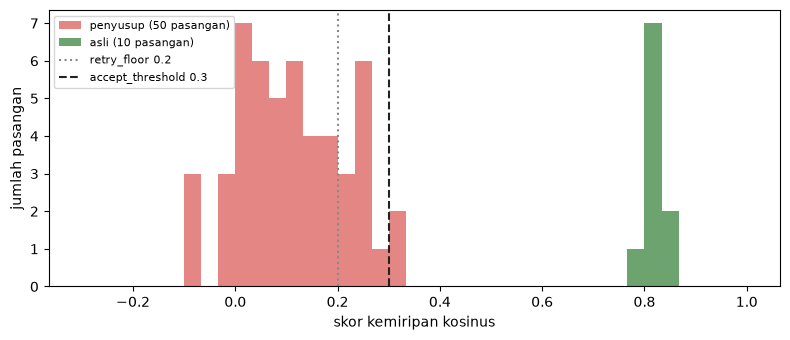

Skor asli terendah 0.794, skor penyusup tertinggi 0.322


In [11]:
import matplotlib.pyplot as plt
import numpy as np

from app.ai import matcher

profil = {nim: matcher.voiceprint_from_bytes(blob) for nim, blob in voiceprints.items()}
pasangan = []
for file, pemilik in uji.drop_duplicates("file")[["file", "pemilik_suara"]].itertuples(index=False):
    try:
        embedding = ai.encoder.embed(ai.prepare((DATA / file).read_bytes()))
    except AudioRejected:
        continue
    for nim, voiceprint in profil.items():
        pasangan.append({"file": file, "nim": nim, "skor": matcher.cosine(embedding, voiceprint), "asli": pemilik == nim})
pasangan = pd.DataFrame(pasangan)
skor_asli = pasangan[pasangan.asli].skor
skor_palsu = pasangan[~pasangan.asli].skor

fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.linspace(-0.3, 1.0, 40)
ax.hist(skor_palsu, bins=bins, alpha=0.7, label=f"penyusup ({len(skor_palsu)} pasangan)", color="#d9534f")
ax.hist(skor_asli, bins=bins, alpha=0.7, label=f"asli ({len(skor_asli)} pasangan)", color="#2e7d32")
ax.axvline(settings.retry_floor, color="#888", linestyle=":", label=f"retry_floor {settings.retry_floor}")
ax.axvline(settings.accept_threshold, color="#222", linestyle="--", label=f"accept_threshold {settings.accept_threshold}")
ax.set_xlabel("skor kemiripan kosinus")
ax.set_ylabel("jumlah pasangan")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print(f"Skor asli terendah {skor_asli.min():.3f}, skor penyusup tertinggi {skor_palsu.max():.3f}")

In [12]:
ambang = np.round(np.arange(0.10, 0.75, 0.05), 2)
tabel_ambang = pd.DataFrame({
    "ambang": ambang,
    "FRR (asli ditolak)": [(skor_asli < t).mean() for t in ambang],
    "FAR (penyusup diterima)": [(skor_palsu >= t).mean() for t in ambang],
})
aman = tabel_ambang[(tabel_ambang["FAR (penyusup diterima)"] == 0) & (tabel_ambang["FRR (asli ditolak)"] == 0)]
print("Ambang tanpa kesalahan pada data ini:", ", ".join(f"{t:.2f}" for t in aman.ambang) or "tidak ada, perlu kompromi")
far_sekarang = (skor_palsu >= settings.accept_threshold).mean()
print(f"Dengan accept_threshold={settings.accept_threshold}: FAR {far_sekarang:.1%}, FRR {(skor_asli < settings.accept_threshold).mean():.1%}")
if far_sekarang > 0:
    print("Ada pasangan penyusup di atas ambang. Pengecekan selisih (min_margin) masih menahan penyusup yang pemilik suaranya terdaftar,")
    print("tetapi untuk orang yang tidak terdaftar hanya ambang yang menahan. Pertimbangkan menaikkan THRESHOLD.")
tabel_ambang.style.format({"FRR (asli ditolak)": "{:.1%}", "FAR (penyusup diterima)": "{:.1%}"})

Ambang tanpa kesalahan pada data ini: 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70
Dengan accept_threshold=0.3: FAR 4.0%, FRR 0.0%
Ada pasangan penyusup di atas ambang. Pengecekan selisih (min_margin) masih menahan penyusup yang pemilik suaranya terdaftar,
tetapi untuk orang yang tidak terdaftar hanya ambang yang menahan. Pertimbangkan menaikkan THRESHOLD.


,ambang,FRR (asli ditolak),FAR (penyusup diterima)
0,0.100000,0.0%,52.0%
1,0.150000,0.0%,32.0%
2,0.200000,0.0%,24.0%
3,0.250000,0.0%,12.0%
4,0.300000,0.0%,4.0%
5,0.350000,0.0%,0.0%
6,0.400000,0.0%,0.0%
7,0.450000,0.0%,0.0%
8,0.500000,0.0%,0.0%
9,0.550000,0.0%,0.0%


### Pasangan suara paling mirip

`ai.closest_pairs` menampilkan pasangan mahasiswa yang voiceprint-nya paling mirip. Jika ada pasangan dengan skor mendekati `accept_threshold`, naikkan `THRESHOLD` atau `MIN_MARGIN` sebelum dipakai di kelas.

In [13]:
pd.DataFrame(ai.closest_pairs(voiceprints, top_k=5), columns=["nim_1", "nim_2", "skor"])

,nim_1,nim_2,skor
0,2702000003,2702000005,0.303663
1,2702000001,2702000002,0.254884
2,2702000001,2702000005,0.250039
3,2702000002,2702000005,0.217139
4,2702000001,2702000003,0.216687


## 8. Coba audio sendiri

`cek_kehadiran(path, klaim_nim)` menjalankan alur absensi yang sama untuk satu file mana pun (wav, webm, m4a, mp3, ...).

In [14]:
def cek_kehadiran(path_audio, klaim_nim):
    hasil = absen(klaim_nim, Path(path_audio).read_bytes())
    skor = f"  skor={hasil['skor']:.3f}" if "skor" in hasil else ""
    print(f"{Path(path_audio).name} mengaku {klaim_nim}: {hasil['keputusan']} ({hasil['alasan']}){skor}")
    print("   ", hasil["pesan"])
    return hasil


cek_kehadiran(DATA / "audio/uji/2702000001_2.webm", "2702000001")
cek_kehadiran(DATA / "audio/uji/tamu_1.wav", "2702000001")
cek_kehadiran(DATA / "audio/uji/2702000003_pendek.wav", "2702000003");

2702000001_2.webm mengaku 2702000001: present (match)  skor=0.802
    Kamu tercatat hadir.


tamu_1.wav mengaku 2702000001: rejected (voice_mismatch)  skor=-0.024
    Suara ini tidak cocok dengan mahasiswa yang terdaftar.
2702000003_pendek.wav mengaku 2702000003: tidak_diproses (too_short)
    Rekaman terlalu pendek, bicaralah minimal 2 detik.


### Rekam dari mikrofon (khusus Colab)

Isi pengaturan lalu ubah `REKAM_SEKARANG = True` dan jalankan sel. Kalimat yang harus dibaca muncul dulu, lalu perekaman berjalan selama `DURASI_DETIK`. Rekaman disimpan ke folder audio dan barisnya ditambahkan ke `manifest.csv`:

- `JENIS_REKAM = "daftar"` → `audio/daftar/<NIM>/<ID_KALIMAT>.webm`. Rekam `K01`, `K02`, `K03`, lalu jalankan ulang notebook dari bagian 3 untuk mendaftarkan NIM baru.
- `JENIS_REKAM = "uji"` → `audio/uji/<NIM>_<waktu>.webm`, langsung dicek kehadirannya.

Di komputer sendiri, rekam dengan aplikasi apa pun, simpan ke folder yang sama, lalu tambahkan barisnya ke `manifest.csv`. Jika `FOLDER_DATA_SENDIRI` kosong, rekaman tersimpan di salinan repo di Colab dan hilang saat runtime berhenti; pakai folder Google Drive agar tersimpan.

In [15]:
import base64
import random
import time
from datetime import datetime

from IPython.display import Javascript

REKAM_SEKARANG = False
NIM_REKAM = "2702000001"
JENIS_REKAM = "uji"
ID_KALIMAT_REKAM = "U01"
DURASI_DETIK = 5

REKAM_JS = """
async function rekamSuara(durasiMs) {
  const stream = await navigator.mediaDevices.getUserMedia({ audio: true });
  const recorder = new MediaRecorder(stream);
  const potongan = [];
  recorder.ondataavailable = (event) => potongan.push(event.data);
  const selesai = new Promise((resolve) => (recorder.onstop = resolve));
  recorder.start();
  await new Promise((resolve) => setTimeout(resolve, durasiMs));
  recorder.stop();
  await selesai;
  stream.getTracks().forEach((track) => track.stop());
  const isi = new Uint8Array(await new Blob(potongan, { type: recorder.mimeType }).arrayBuffer());
  let biner = "";
  for (let i = 0; i < isi.length; i += 1) biner += String.fromCharCode(isi[i]);
  return btoa(biner);
}
"""


def kalimat_untuk(id_kalimat, nim):
    template = naskah.set_index("id_kalimat").kalimat[id_kalimat]
    nama = mahasiswa.set_index("nim").nama.get(nim, "<nama>")
    return template.format(nama=nama, nim=nim, kode=f"{random.randint(0, 999_999):06d}")


def rekam_mikrofon(detik):
    from google.colab.output import eval_js

    display(Javascript(REKAM_JS))
    return base64.b64decode(eval_js(f"rekamSuara({int(detik * 1000)})"))


def simpan_rekaman(isi_audio, nim, jenis, id_kalimat):
    if jenis == "daftar":
        tujuan = DATA / "audio" / "daftar" / nim / f"{id_kalimat}.webm"
    else:
        tujuan = DATA / "audio" / "uji" / f"{nim}_{datetime.now():%Y%m%d-%H%M%S}.webm"
    tujuan.parent.mkdir(parents=True, exist_ok=True)
    tujuan.write_bytes(isi_audio)
    baris = {
        "file": tujuan.relative_to(DATA).as_posix(),
        "pemilik_suara": nim,
        "jenis": jenis,
        "klaim_nim": nim,
        "harapan": "hadir" if jenis == "uji" else "",
        "id_kalimat": id_kalimat,
    }
    pd.DataFrame([baris]).to_csv(DATA / "manifest.csv", mode="a", header=False, index=False)
    print("Tersimpan:", baris["file"], "(baris baru ditambahkan ke manifest.csv)")
    return tujuan


if REKAM_SEKARANG:
    if not DI_COLAB:
        raise RuntimeError("Perekaman mikrofon hanya tersedia di Colab. Di lokal, simpan file ke folder audio lalu tambahkan ke manifest.csv.")
    print("Bacakan setelah perekaman dimulai:\n   ", kalimat_untuk(ID_KALIMAT_REKAM, NIM_REKAM))
    time.sleep(2)
    print(f"Merekam {DURASI_DETIK} detik...")
    rekaman = rekam_mikrofon(DURASI_DETIK)
    display(Audio(ai.prepare(rekaman), rate=16000))
    path_rekaman = simpan_rekaman(rekaman, NIM_REKAM, JENIS_REKAM, ID_KALIMAT_REKAM)
    if JENIS_REKAM == "uji":
        cek_kehadiran(path_rekaman, NIM_REKAM)
else:
    print("Ubah REKAM_SEKARANG = True untuk merekam dari mikrofon.")

Ubah REKAM_SEKARANG = True untuk merekam dari mikrofon.


### Unggah file (khusus Colab)

Ubah `UNGGAH_SEKARANG = True` untuk mengunggah satu atau beberapa file dan mengeceknya sebagai `NIM_REKAM`.

In [16]:
UNGGAH_SEKARANG = False

if UNGGAH_SEKARANG and DI_COLAB:
    from google.colab import files

    for nama_file, isi in files.upload().items():
        hasil = absen(NIM_REKAM, isi)
        print(f"{nama_file} mengaku {NIM_REKAM}: {hasil['keputusan']} ({hasil['alasan']})  {hasil['pesan']}")
else:
    print("Ubah UNGGAH_SEKARANG = True (di Colab) untuk mengunggah file.")

Ubah UNGGAH_SEKARANG = True (di Colab) untuk mengunggah file.


## 9. Langkah berikutnya

- **Menambah mahasiswa** tidak perlu melatih ulang model: rekam `K01`–`K03`, tambahkan ke manifest, jalankan ulang. Di backend, ini adalah `POST /api/enroll`.
- **Menyetel ambang**: kumpulkan rekaman kelas sungguhan, lihat grafik sebaran skor dan tabel ambang di bagian 7, lalu isi `THRESHOLD` dan `MIN_MARGIN` di `backend/.env`.
- **Melatih ulang (*fine-tuning*)** baru masuk akal setelah ada data cukup (kira-kira 50+ mahasiswa × 10+ klip) dari `ARCHIVE_DIR` backend. Setelah itu arahkan `ENCODER` ke model baru dan panggil `rebuild_voiceprints()`. Lihat `docs/ai-integration.md` bagian 5.